In [ ]:
!pip install ultralytics
%pip install roboflow

# !pip install easyocr
# !pip install paddleocr
# !pip install paddlepaddle


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

import os
import shutil
import yaml
import warnings

import wandb
import random

import cv2
from PIL import Image
from ultralytics import YOLO
# import easyocr

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   -------------- ------------------------- 0.5/1.4 MB 4.2 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 3.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 4.2 MB/s eta 0:00:03
   ------ --------------------------------- 1.6/9.3 MB 3.8 MB/s eta 0:00:03
   ---------- ----------------------------- 2.4/9.3 MB 3.9 MB/s eta 0:00:02
   ------------- -------------------------- 3.1/9.3 MB 3.9 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.3 MB 3.9 MB/s eta 0:00:02
   -------------------- ------------------- 4.7/9.3 MB 3.9 MB/s eta 0:00:02
   ------------------------ --------------- 5.8/9.3 MB 3.9 MB/s eta 0:00:01
   ---------------------------- ----------- 6.6/9.3 MB 3.9 MB/s eta 0:00:01
   ---------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\moham\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/43.8 MB ? eta -:--:--
    --------------------------------------- 0.8/43.8 MB 8.5 MB/s eta 0:00:06
   - -------------------------------------- 1.6/43.8 MB 5.2 MB/s eta 0:00:09
   -- ------------------------------------- 2.4/43.8 MB 4.6 MB/s eta 0:00:09
   -- ------------------------------------- 3.1/43.8 MB 4.4 MB/s eta 0:00:10
   --- ------------------------------------ 3.9/43.8 MB 4.3 MB/s eta 0:00:10
   ---- ----------------------------------- 4.7/43.8 MB 4.1 MB/s eta 0:00:10
   ----- ---------------------------------- 5.5/43.8 MB 4.1 MB/s eta 0:00:10
   ----- ---------------------------------- 6.6/43.8 MB 4.0 MB/s eta 0:00:10
   ------ --------------------------------- 7.3/43.8 MB 4.0 MB/s eta 0:00:10
   ------- -------------------------------- 7.9/43.8 MB 3.9 MB/s eta 0:00:10
   ------- -------------------------------- 8.1/43.8 MB 3.8 MB/s eta 0:00:10
   --

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\moham\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
from roboflow import Roboflow

rf = Roboflow(api_key="KGqdrhhg9OUgSpREXZLR")
project = rf.workspace("mousa-9wtzt").project("egypt-plate-merged-erxeu")
version = project.version(1)
dataset = version.download("yolov8")
                

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to egypt-plate-merged-1 in yolov8:: 100%|██████████| 14800/14800 [00:02<00:00, 6932.50it/s]


In [ ]:
# Paths to your dataset (images and labels)
images_path = '/kaggle/working/egypt-plate-merged-1/train/images'
labels_path = '/kaggle/working/egypt-plate-merged-1/train/labels'

image_files = sorted(os.listdir(images_path))
label_files = sorted(os.listdir(labels_path))

Image Shape: (640, 640, 3)


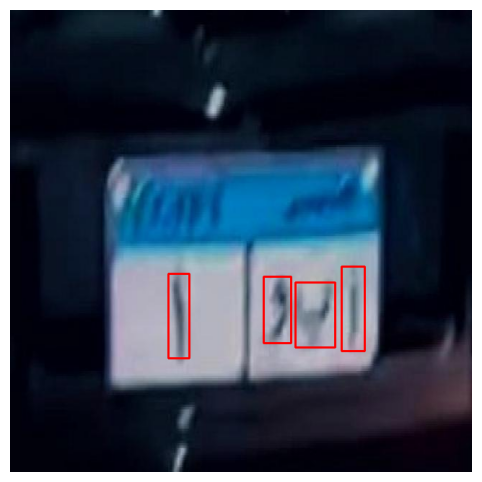

In [ ]:
# Function to load bounding boxes from the label file
def load_bounding_boxes(label_file):
    bounding_boxes = []
    with open(label_file, 'r') as file:
        for line in file.readlines():
            values = line.strip().split()
            class_id = int(values[0])  # Class ID (optional if needed)
            x_center = float(values[1])
            y_center = float(values[2])
            width = float(values[3])
            height = float(values[4])
            bounding_boxes.append([x_center, y_center, width, height])
    return bounding_boxes

# Function to draw bounding boxes on the image
def draw_bounding_boxes(image, bounding_boxes):
    h, w = image.shape[:2]
    for bbox in bounding_boxes:
        x_center, y_center, box_width, box_height = bbox
        # Convert YOLO format to corner coordinates
        x1 = int((x_center - box_width / 2) * w)
        y1 = int((y_center - box_height / 2) * h)
        x2 = int((x_center + box_width / 2) * w)
        y2 = int((y_center + box_height / 2) * h)
        # Draw the rectangle on the image
        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)
    return image

# Function to display image with bounding boxes
def plot_image_with_boxes(image_file, label_file):
    # Load the image
    image = cv2.imread(image_file)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert from BGR to RGB for matplotlib
    
    # Print the shape of the image
    print(f"Image Shape: {image.shape}")
    
    # Load bounding boxes from the corresponding label file
    bounding_boxes = load_bounding_boxes(label_file)
    
    # Draw bounding boxes on the image
    image_with_boxes = draw_bounding_boxes(image, bounding_boxes)
    
    # Display the image with bounding boxes
    plt.figure(figsize=(8, 6))
    plt.imshow(image_with_boxes)
    plt.axis('off')
    plt.show()

# List all images and labels
image_files = sorted(os.listdir(images_path))
label_files = sorted(os.listdir(labels_path))

# Plot a sample image with bounding boxes
sample_index = 0  # Change this to view a different sample
sample_image_file = os.path.join(images_path, image_files[sample_index])
sample_label_file = os.path.join(labels_path, label_files[sample_index])

plot_image_with_boxes(sample_image_file, sample_label_file)

Image Shape: (640, 640, 3)


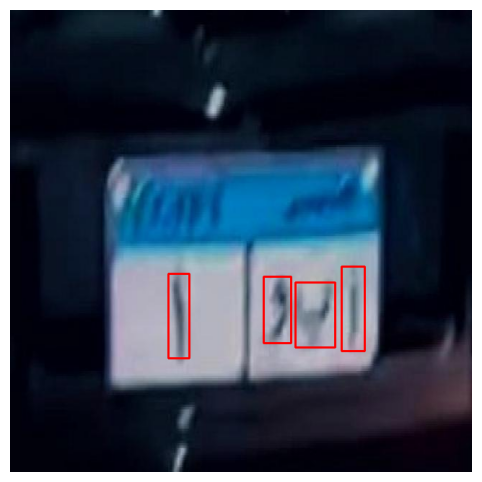

Image Shape: (640, 640, 3)


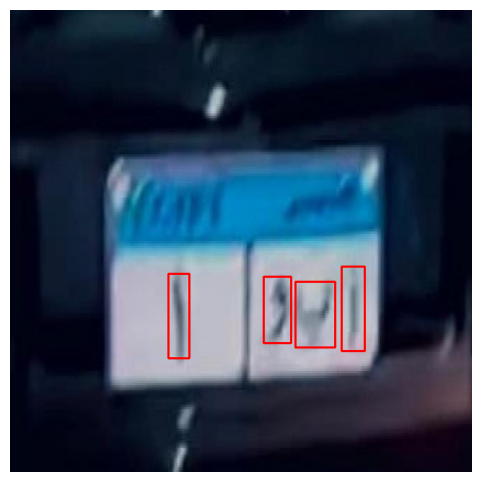

Image Shape: (640, 640, 3)


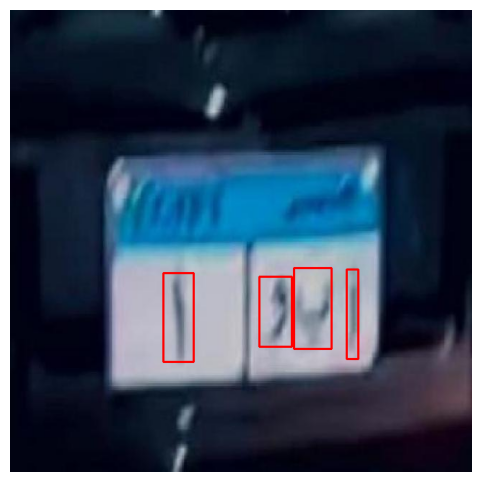

Image Shape: (640, 640, 3)


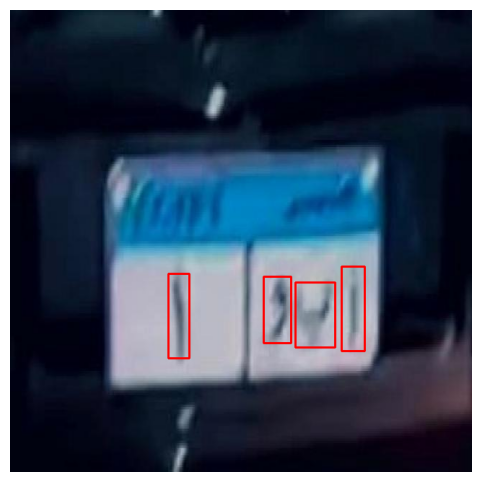

Image Shape: (640, 640, 3)


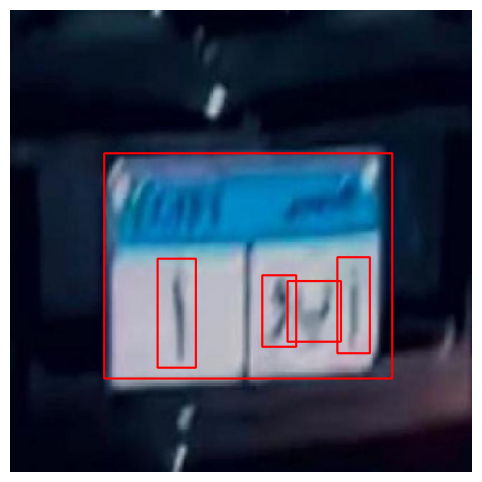

Image Shape: (640, 640, 3)


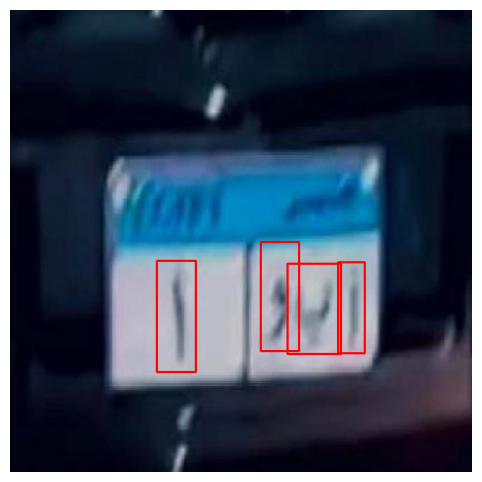

Image Shape: (640, 640, 3)


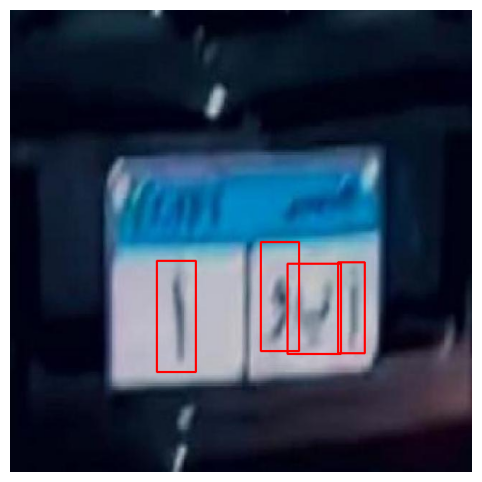

Image Shape: (640, 640, 3)


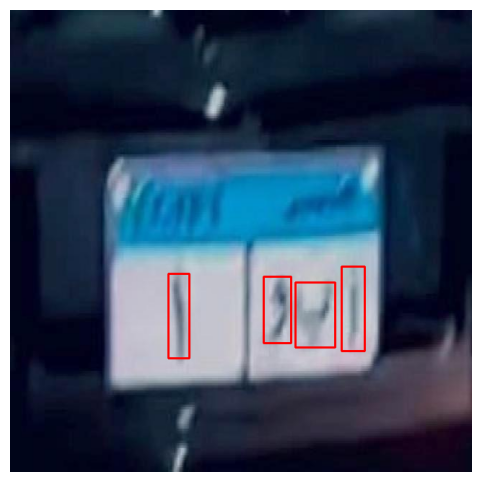

Image Shape: (640, 640, 3)


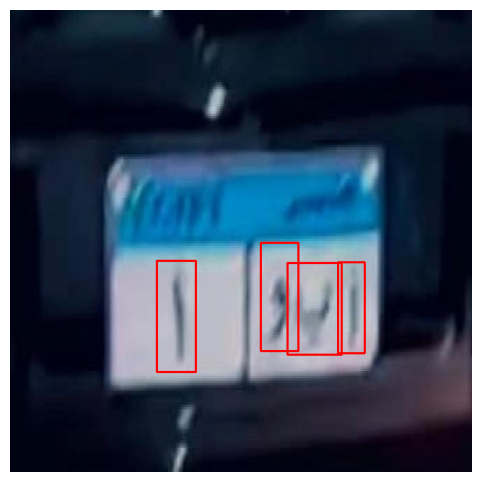

Image Shape: (640, 640, 3)


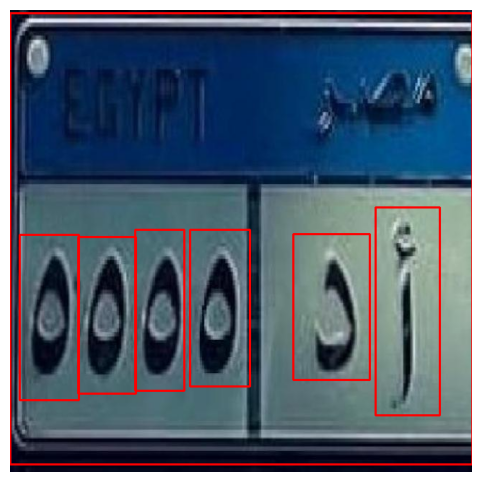

In [ ]:
for sample_index in range (10):
    sample_image_file = os.path.join(images_path, image_files[sample_index])
    sample_label_file = os.path.join(labels_path, label_files[sample_index])

    plot_image_with_boxes(sample_image_file, sample_label_file)

In [ ]:
# # Directories
# label_dir = '/kaggle/input/egyptian-cars-plates/EALPR Vechicles dataset/Vehicles Labeling'
# image_dir = '/kaggle/input/egyptian-cars-plates/EALPR Vechicles dataset/Vehicles'
# working_dir = '/kaggle/working/combined_dataset'

# # Create a writable directory in /kaggle/working
# os.makedirs(working_dir, exist_ok=True)

# # List all images and labels
# image_files = [f for f in os.listdir(image_dir) if f.endswith('.jpg')]
# label_files = [f for f in os.listdir(label_dir) if f.endswith('.txt')]

# # Copy the images and matching label files to the writable directory
# for image_file in image_files:
#     # Get the base filename without the extension (e.g., image1.jpg -> image1)
#     base_name = os.path.splitext(image_file)[0]
    
#     # Find the corresponding label file (e.g., image1.txt)
#     label_file = f"{base_name}.txt"
    
#     if label_file in label_files:
#         # Copy the image and label file to the working directory
#         shutil.copy(os.path.join(image_dir, image_file), os.path.join(working_dir, image_file))
#         shutil.copy(os.path.join(label_dir, label_file), os.path.join(working_dir, label_file))
# #         print(f"Copied {image_file} and {label_file} to {working_dir}")
#     else:
#         print(f"No label found for {image_file}")

# print("Image and label files have been copied to the writable directory.")

In [ ]:
# # Create the data dictionary
# data_dict = {
#     'train': "/kaggle/working/combined_dataset",  # Path to the training images
#     'val': "/kaggle/working/combined_dataset",    # Use the same for validation; update if you have a separate validation set
#     'nc': 1,             # Number of classes (adjust if you have more)
#     'names': ['car_plate']  # Class names (adjust as needed)
# }

# # Specify the path for the YAML file
# yaml_file_path = '/kaggle/working/car_plate_data.yaml'

# # Write the dictionary to a YAML file
# with open(yaml_file_path, 'w') as yaml_file:
#     yaml.dump(data_dict, yaml_file)

# print(f"YAML file created at: {yaml_file_path}")

In [ ]:
file_path = '/kaggle/working/egypt-plate-merged-1/train/labels/00003_jpg.rf.3b1da5d8c56f38fb999fb6a30abb5936.txt'

try:
    with open(file_path, 'r') as file:
        annotations = file.read()
    print(annotations)
except FileNotFoundError:
    print("The specified file was not found.")

13 0.74296875 0.64609375 0.05 0.1828125
14 0.6609375 0.659375 0.0859375 0.140625
33 0.578125 0.6484375 0.059375 0.14375
1 0.36484375 0.66171875 0.0453125 0.1828125


In [ ]:
# Import YOLOv8 from ultralytics
from ultralytics import YOLO

# Initialize the YOLOv8 model
model_ocr = YOLO("yolov8m.pt")  # Use the YOLOv8m pre-trained model

# Train the model
model_ocr.train(
    data='/kaggle/working/egypt-plate-merged-1/data.yaml',  # Path to your dataset configuration file
    epochs=40,  # Number of training epochs
    batch=32,  # Batch size
    imgsz=640,  # Image size for training
    cache=True,  # Cache images for faster training
    augment=False,  # Enable data augmentation
    project="runs/train",  # Directory to save training results
    name='yolov8m_car_plate',  # Experiment name
    workers=4,  # Number of workers for data loading
    device=0,  # Use GPU (0) or CPU (-1)
    lr0=0.0002  # Initial learning rate
)

# Evaluate the model after training (optional)
metrics = model_ocr.val()

# Save the trained model weights (optional)
model_ocr.export(format="torchscript")  # Export trained model


Ultralytics 8.3.105 🚀 Python-3.10.12 torch-2.4.1+cu121 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: task=detect, mode=train, model=yolov8m.pt, data=/kaggle/working/egypt-plate-merged-1/data.yaml, epochs=40, time=None, patience=100, batch=32, imgsz=640, save=True, save_period=-1, cache=True, device=0, workers=4, project=runs/train, name=yolov8m_car_plate2, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_labels=Tru

train: Scanning /kaggle/working/egypt-plate-merged-1/train/labels.cache... 6645 images, 71 backgrounds, 0 corrupt: 100%|██████████| 6645/6645 [00:00<?, ?it/s]


WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 28, len(boxes) = 46519. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
WARNING ⚠️ cache='ram' may produce non-deterministic training results. Consider cache='disk' as a deterministic alternative if your disk space allows.


train: Caching images (7.6GB RAM): 100%|██████████| 6645/6645 [00:08<00:00, 747.30it/s]

albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, num_output_channels=3, method='weighted_average'), CLAHE(p=0.01, clip_limit=(1, 4.0), tile_grid_size=(8, 8))



os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
val: Scanning /kaggle/working/egypt-plate-merged-1/valid/labels.cache... 341 images, 16 backgrounds, 0 corrupt: 100%|██████████| 341/341 [00:00<?, ?it/s]

... (128 outputs left out)

WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 7, len(boxes) = 2565. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
WARNING ⚠️ cache='ram' may produce non-deterministic training results. Consider cache='disk' as a deterministic alternative if your disk space allows.



val: Caching images (0.4GB RAM): 100%|██████████| 341/341 [00:00<00:00, 561.82it/s]
os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 11/11 [00:07<00:00,  1.48it/s]


                   all        341       2565      0.886      0.905      0.886      0.543
                     1        126        145      0.908       0.95      0.932      0.489
                     2        127        134      0.915      0.961      0.921      0.553
                     3        113        129      0.951      0.953       0.95      0.606
                     4        109        117      0.935      0.979      0.943      0.609
                     5        116        130      0.912      0.954      0.916      0.498
                     6        125        148      0.873       0.93      0.862      0.541
                     7        136        150      0.971      0.973      0.965      0.618
                     8        120        131      0.947      0.985      0.965      0.593
                     9        124        132      0.927      0.977      0.948      0.563
         License Plate        267        295      0.989      0.941      0.964      0.874
                  aai

'runs/train/yolov8m_car_plate2/weights/best.torchscript'

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/val_batch0_pred.jpg


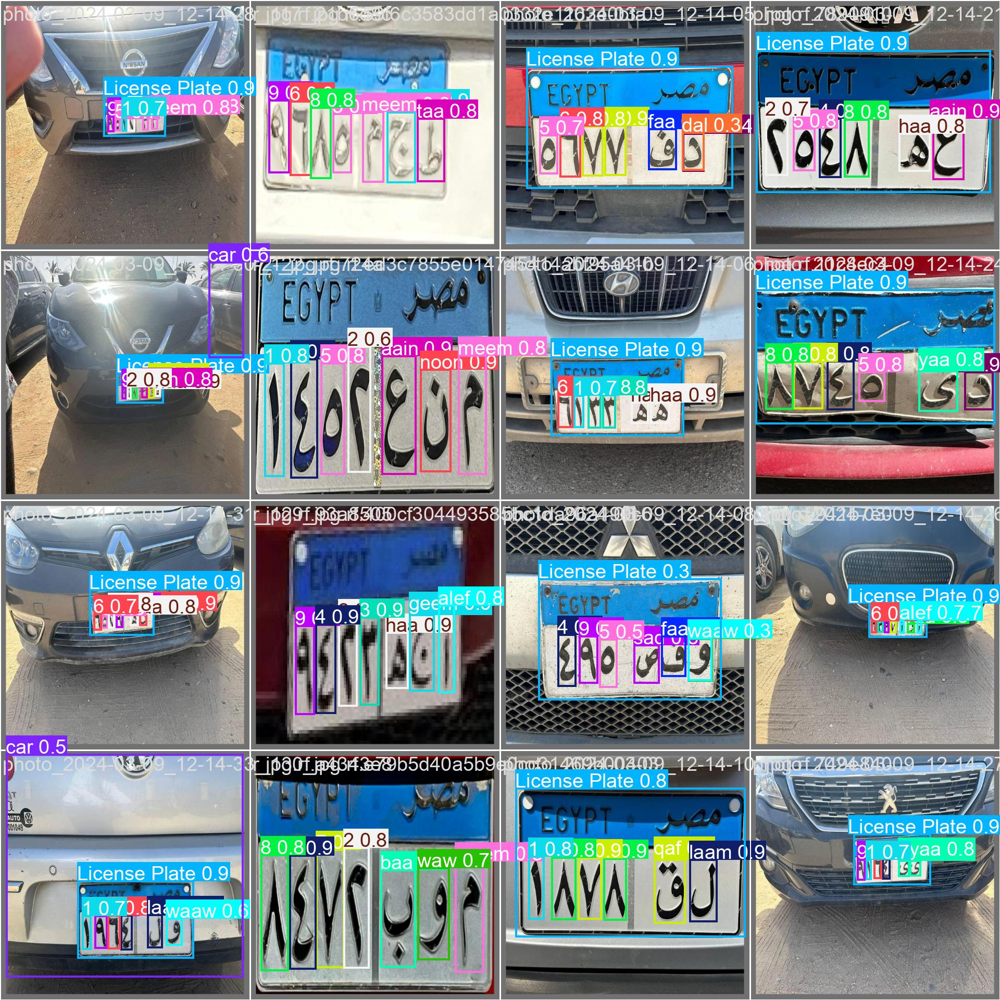

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/val_batch1_labels.jpg


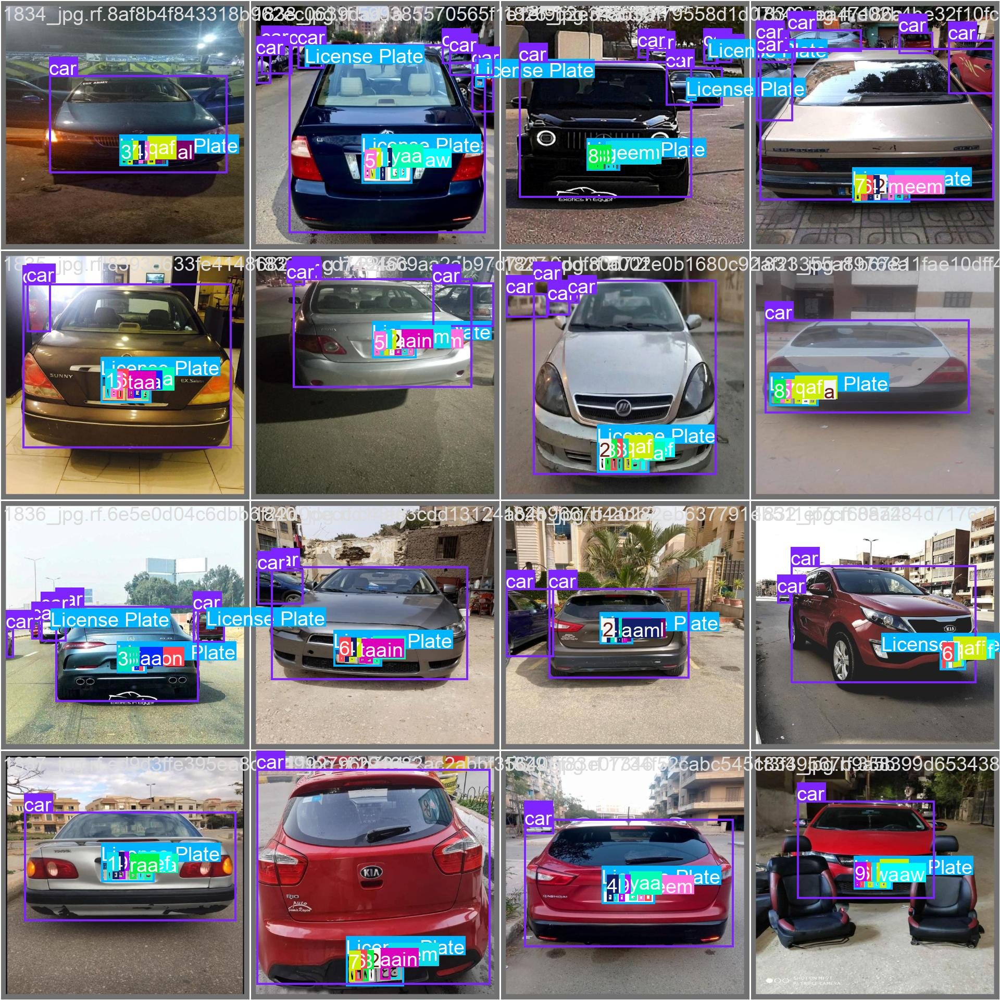

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/train_batch1.jpg


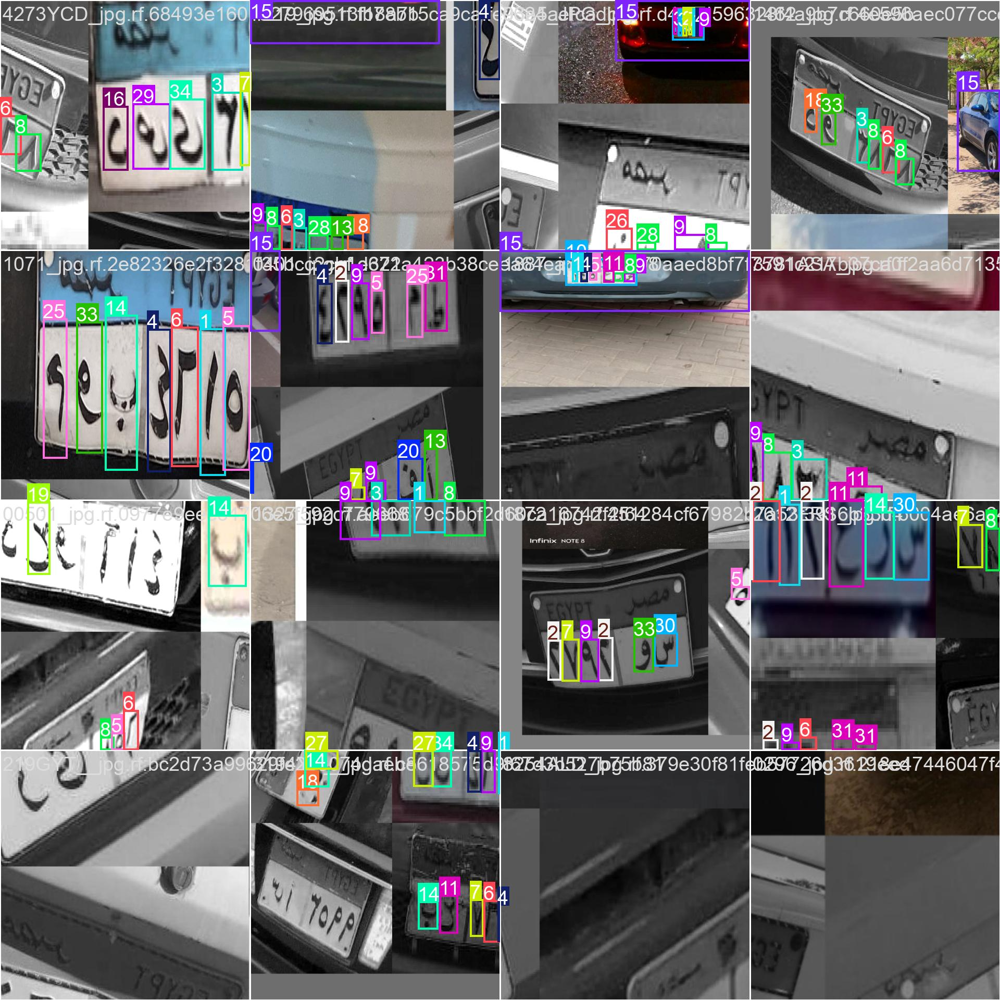

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/labels_correlogram.jpg


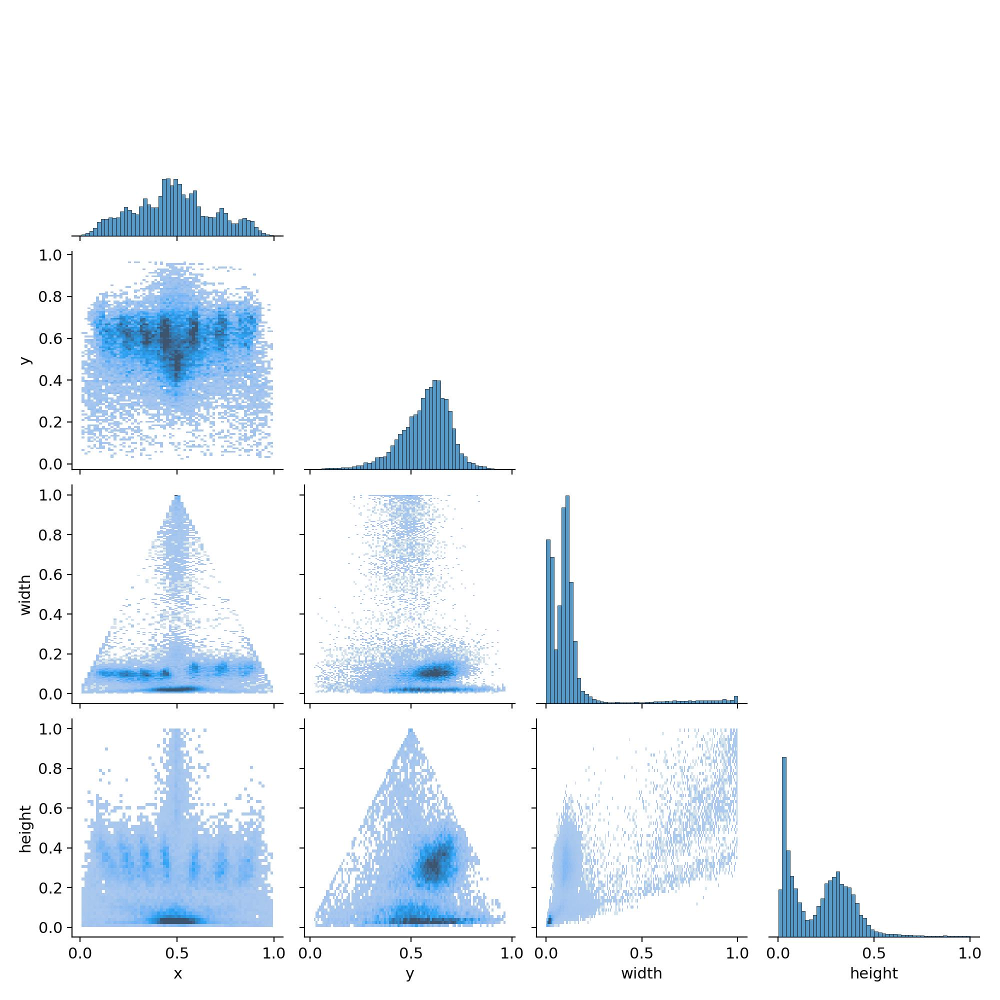

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/val_batch2_pred.jpg


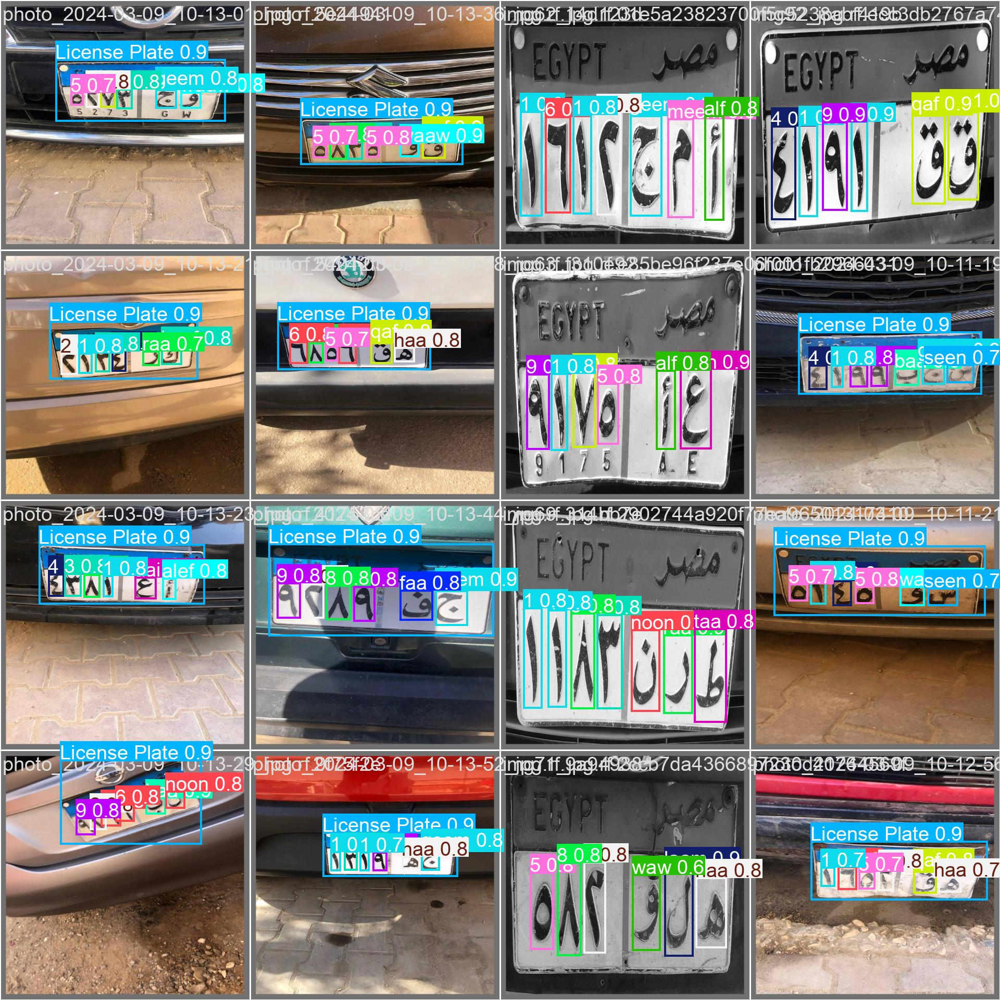

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/confusion_matrix.png


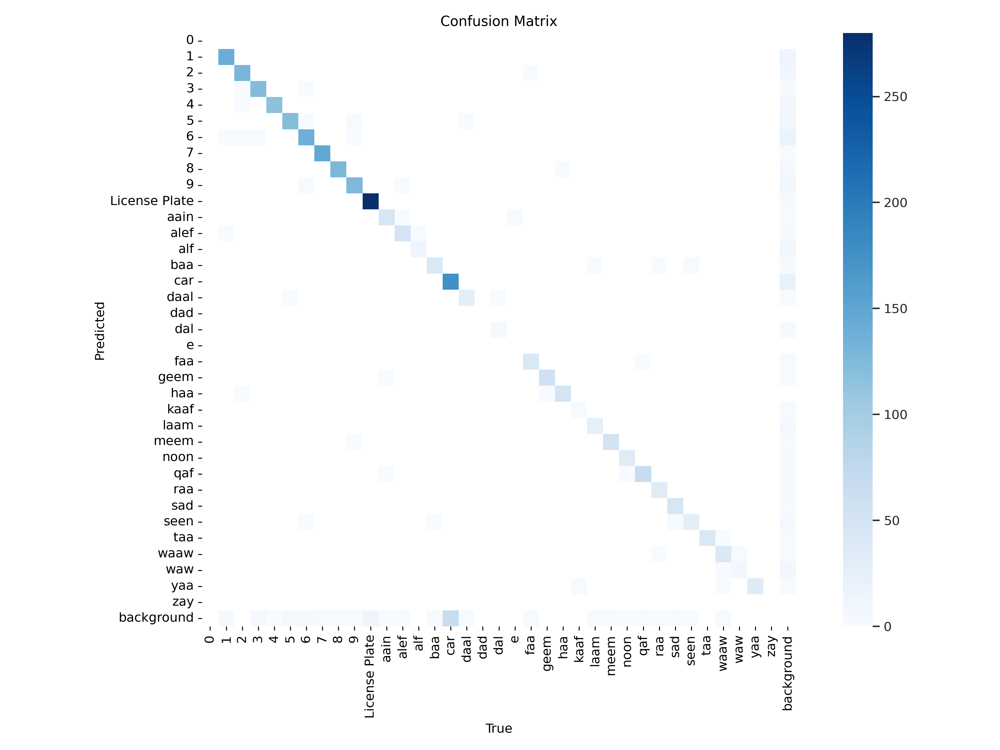

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/val_batch0_labels.jpg


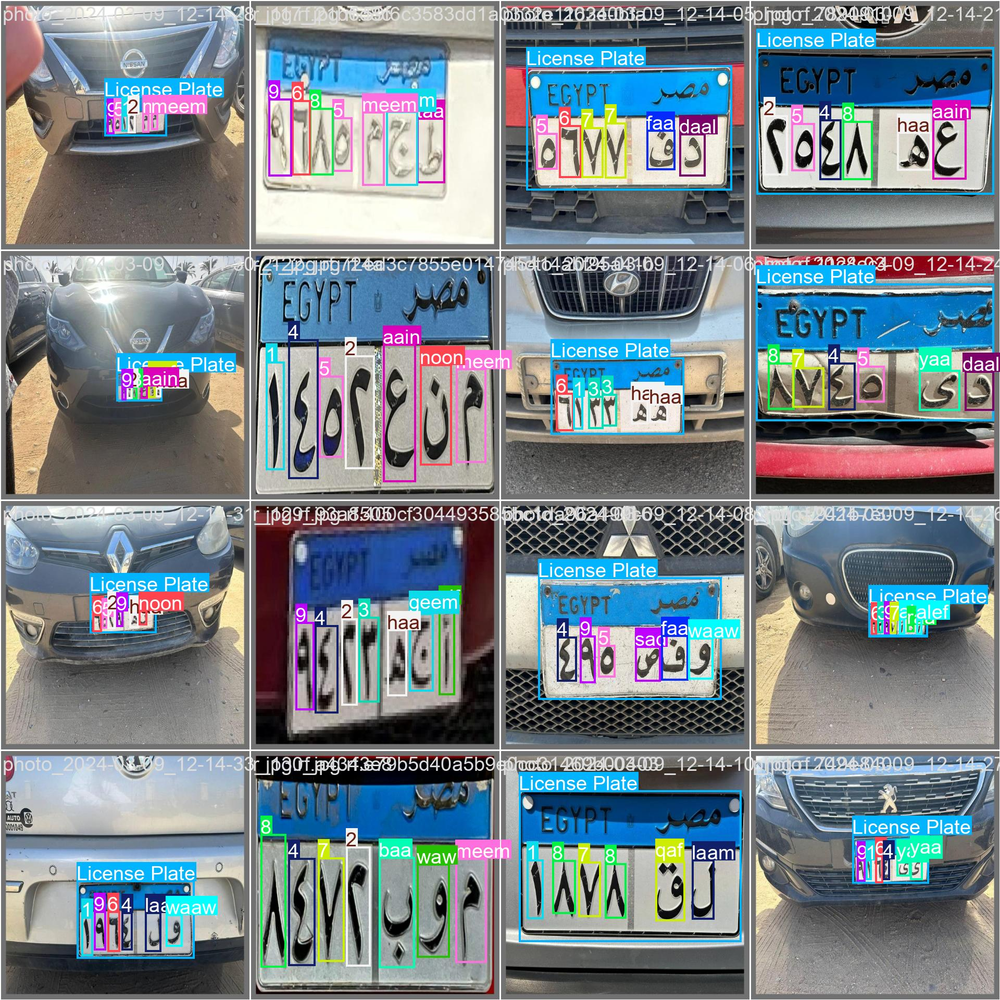

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/val_batch1_pred.jpg


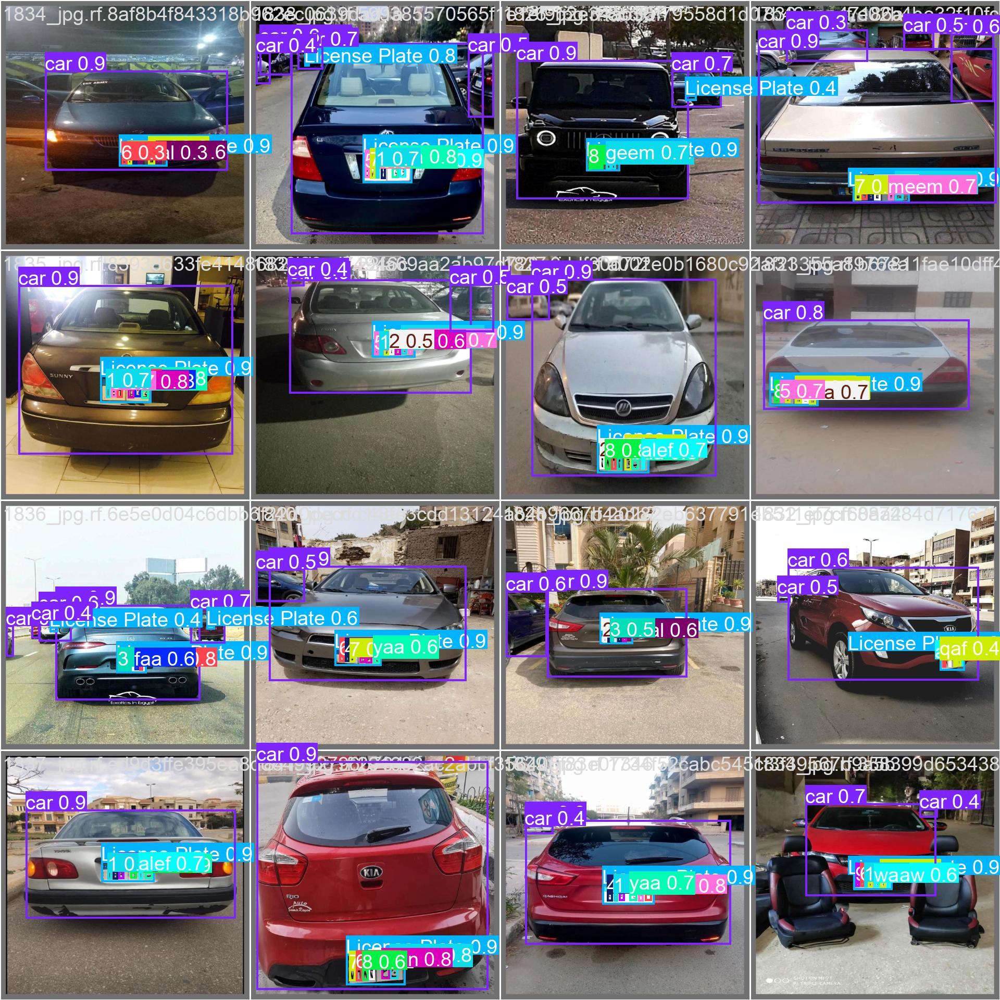

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/labels.jpg


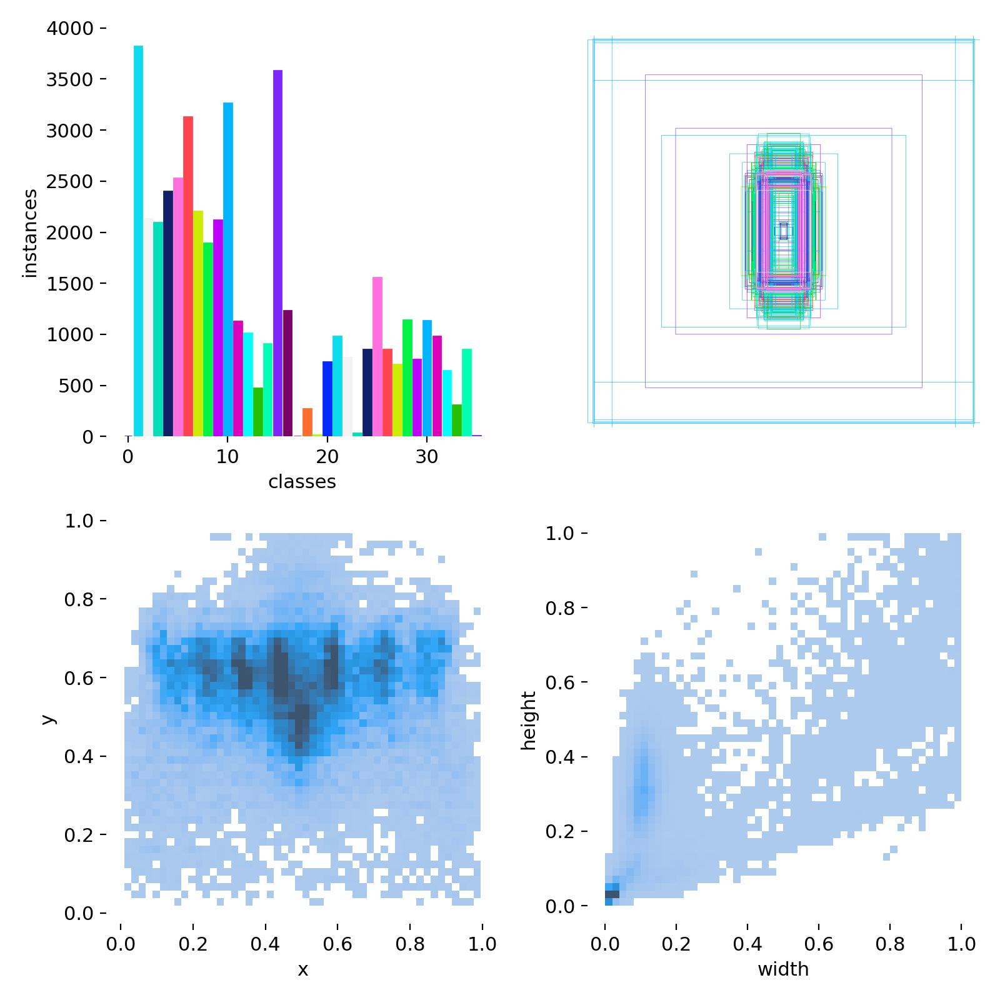

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/train_batch6240.jpg


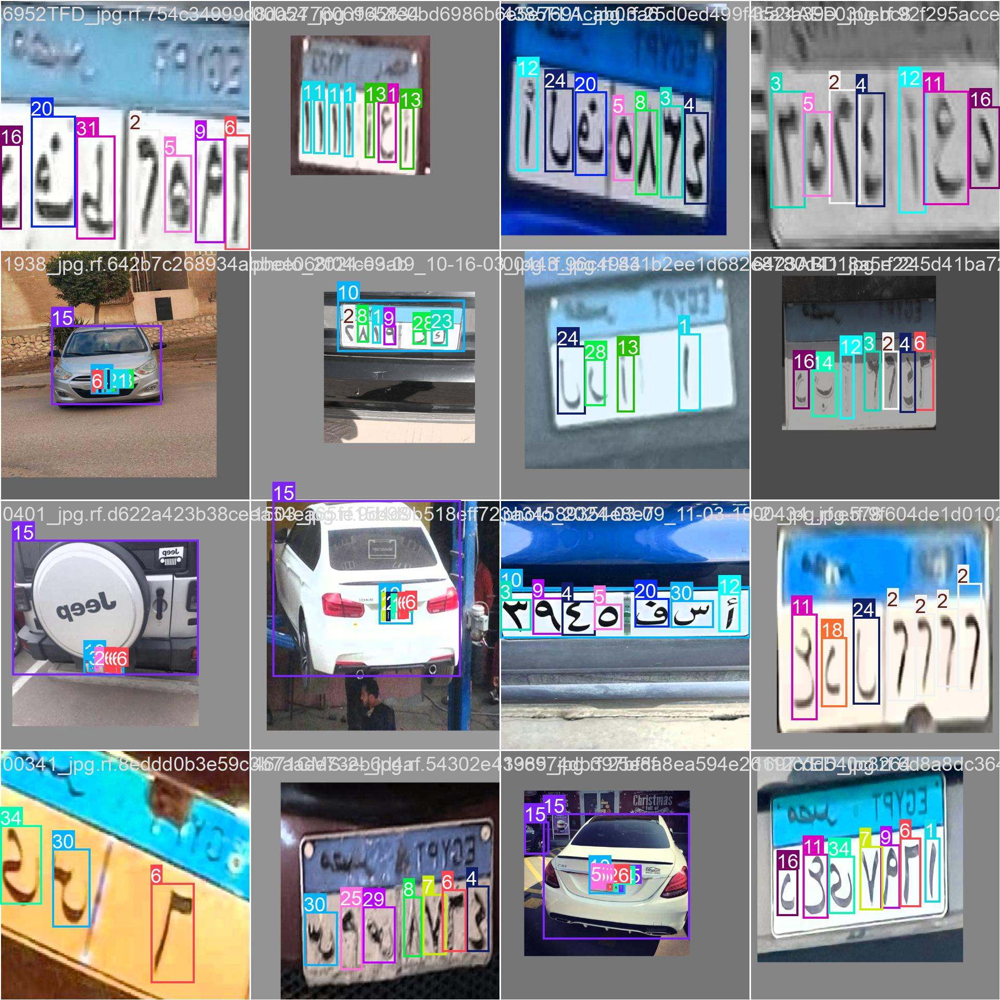

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/P_curve.png


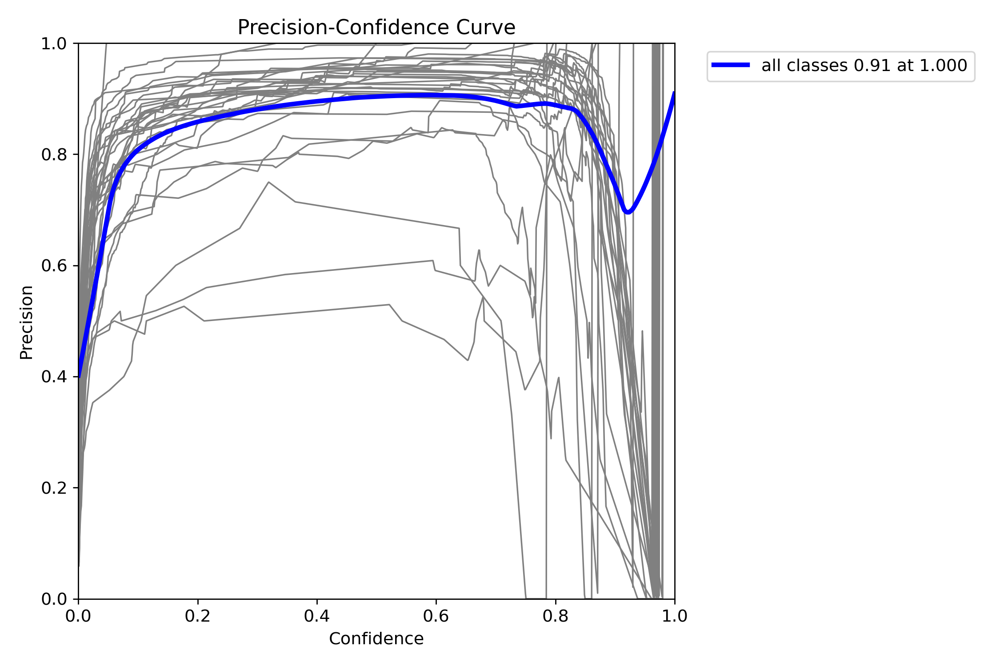

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/F1_curve.png


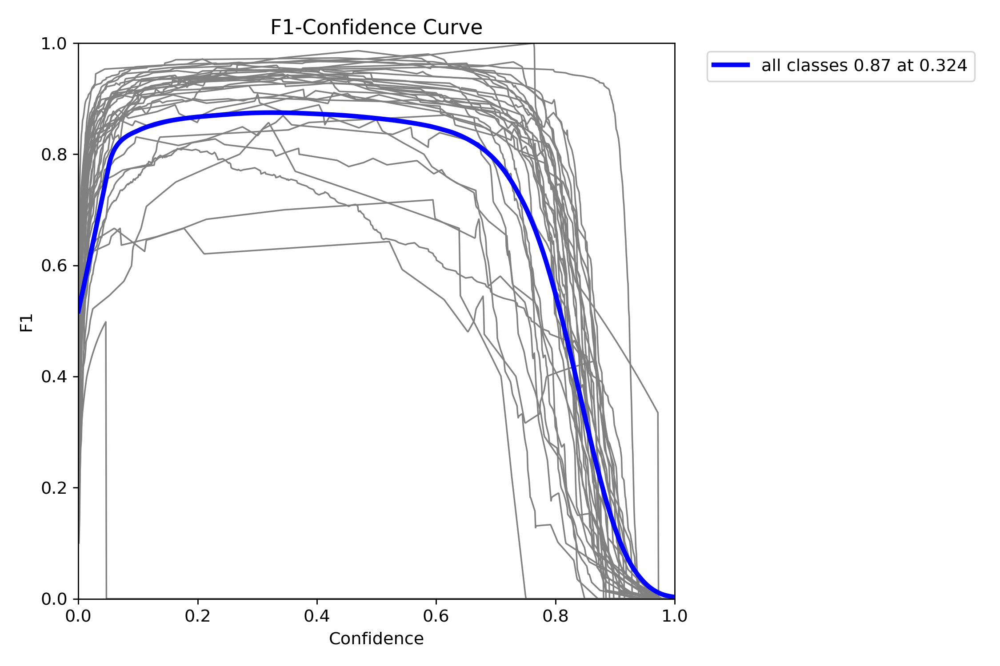

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/train_batch6241.jpg


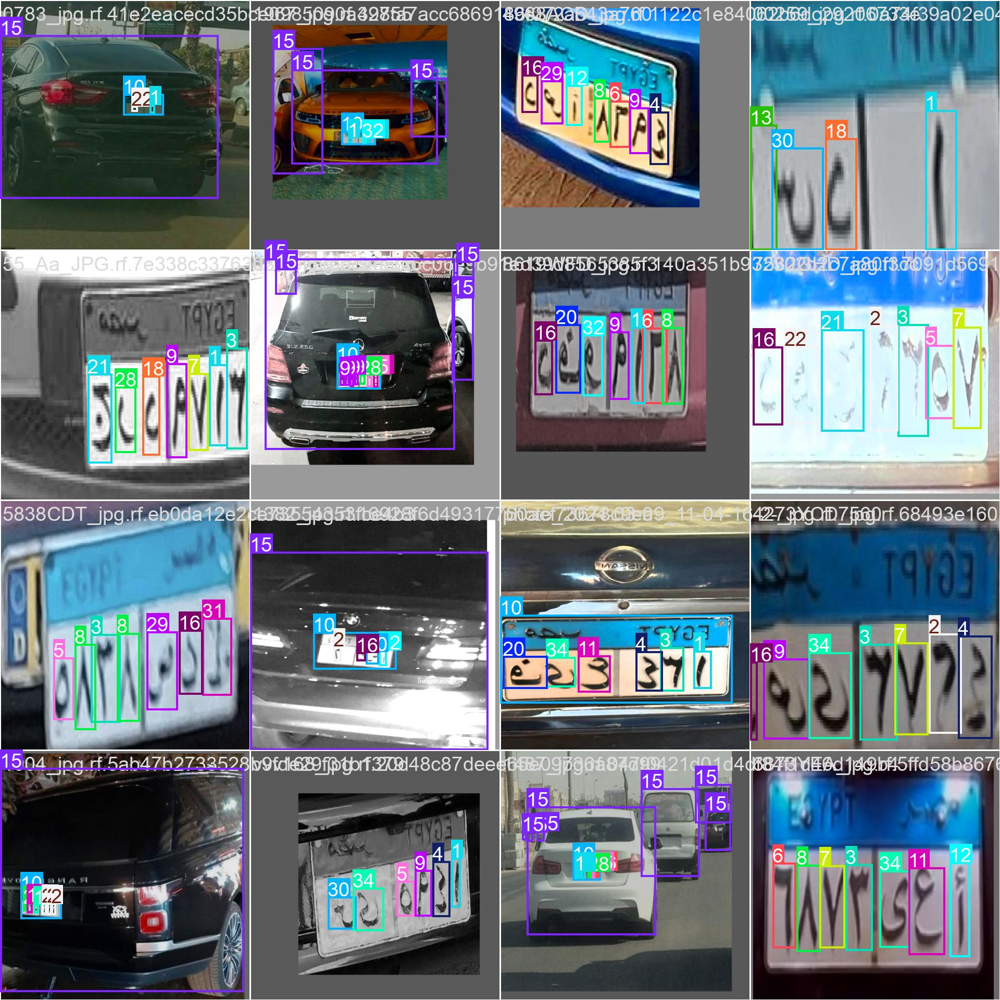

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/confusion_matrix_normalized.png


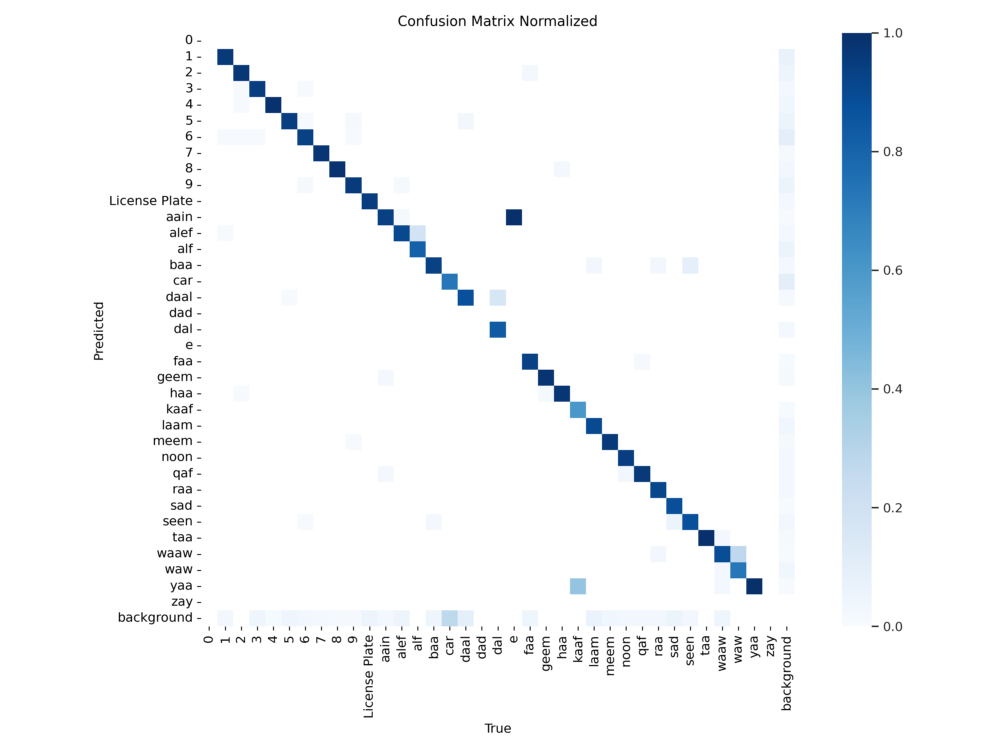

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/train_batch0.jpg


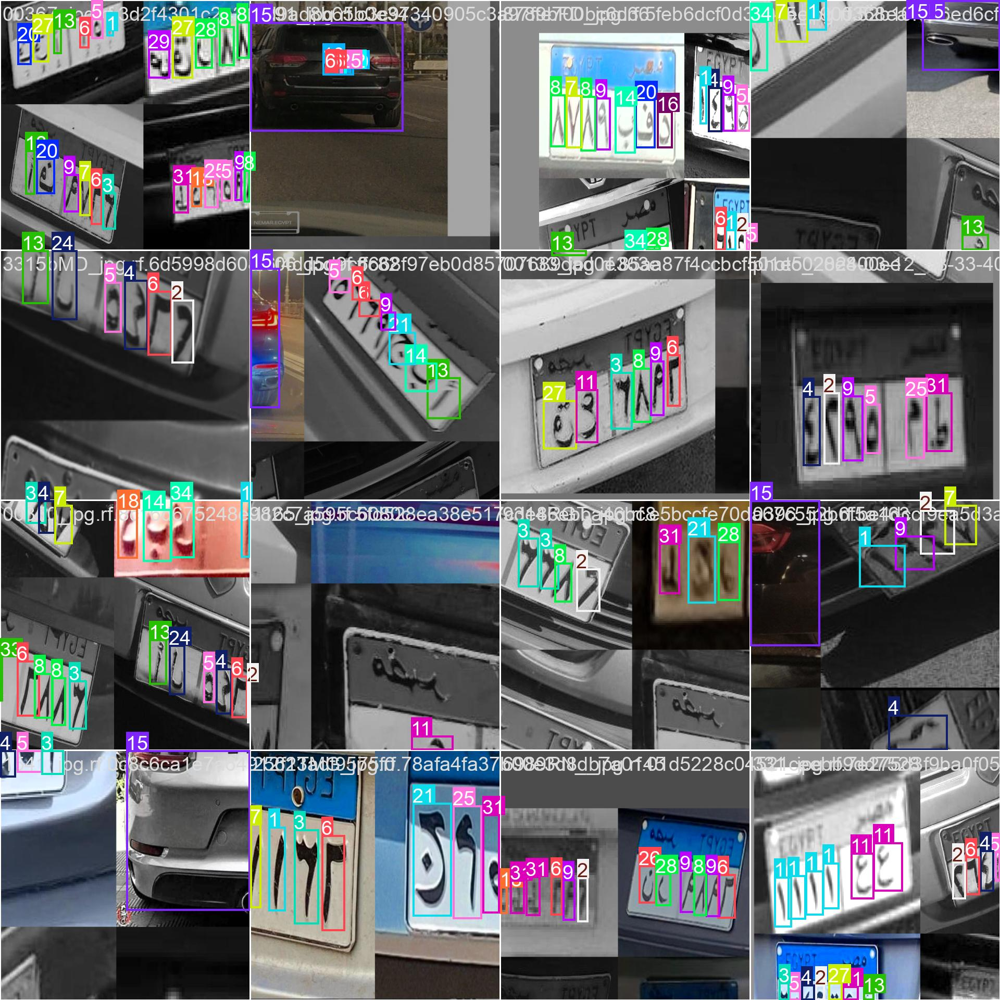

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/train_batch2.jpg


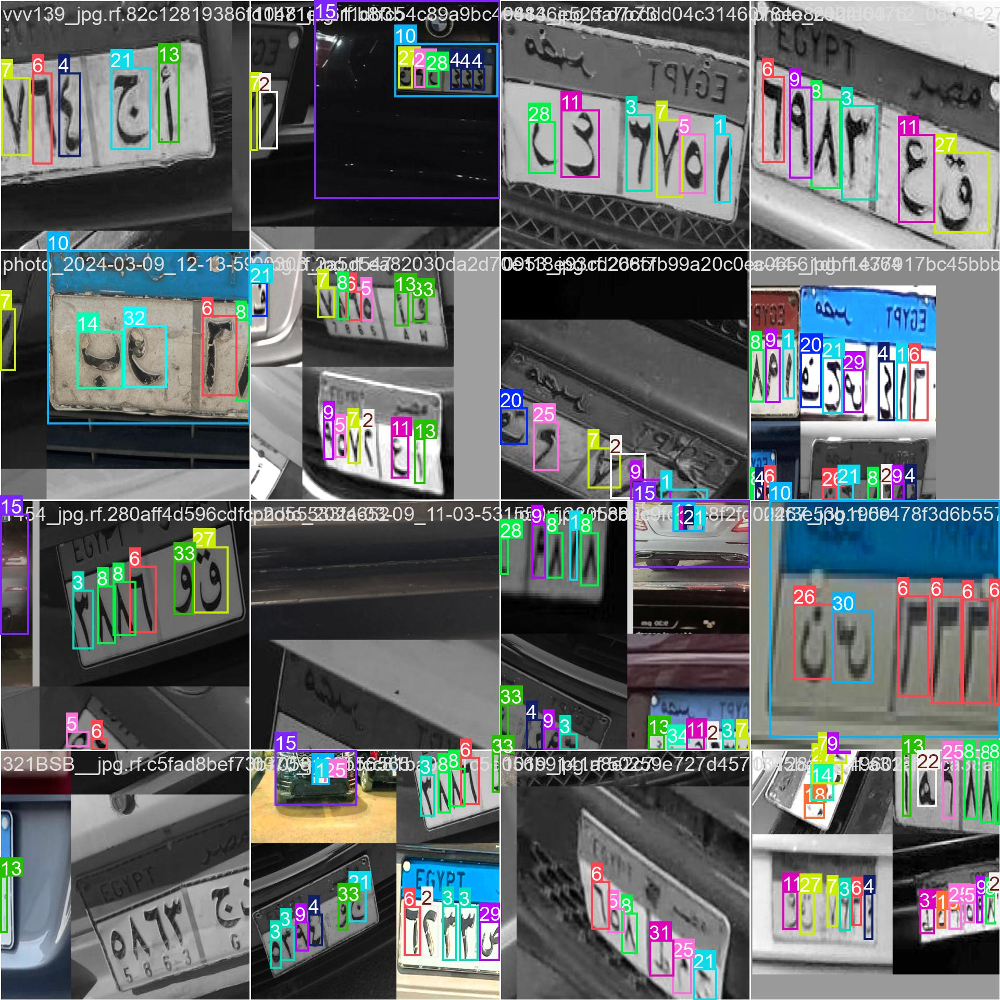

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/R_curve.png


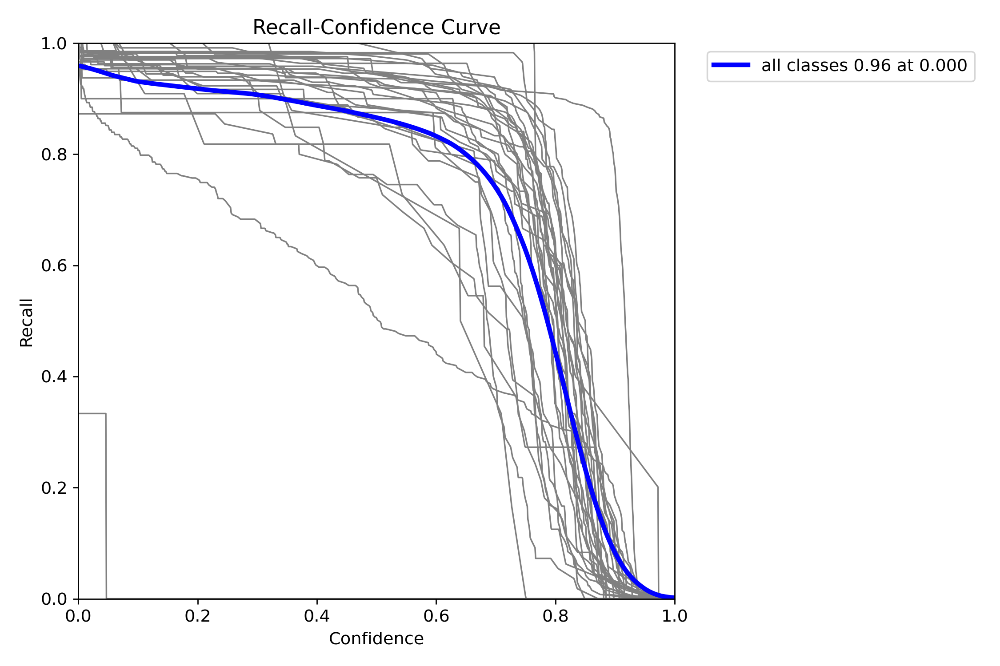

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/PR_curve.png


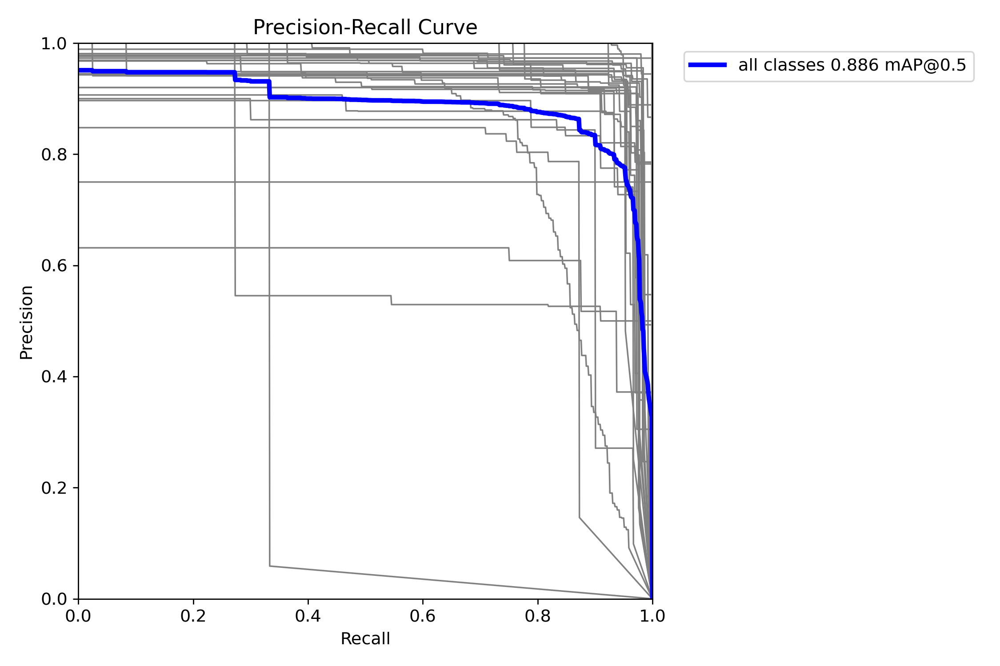

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/results.png


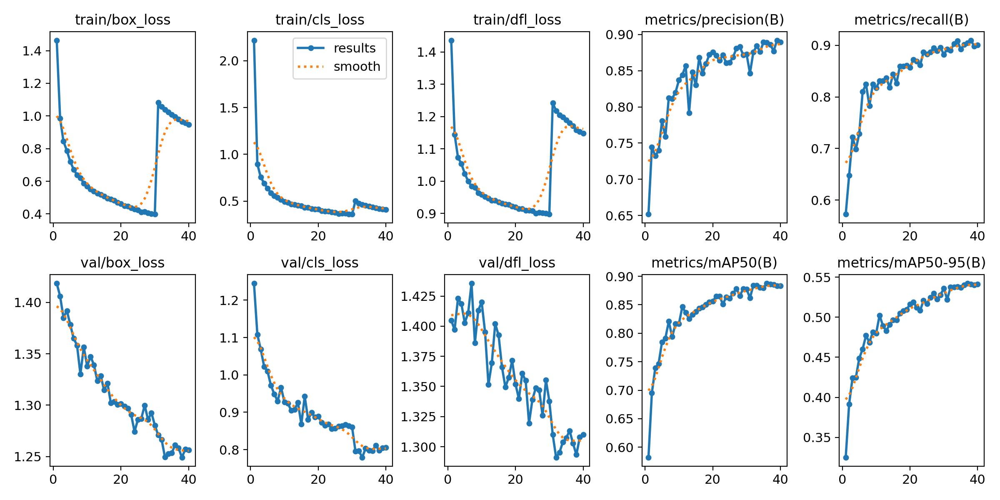

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/val_batch2_labels.jpg


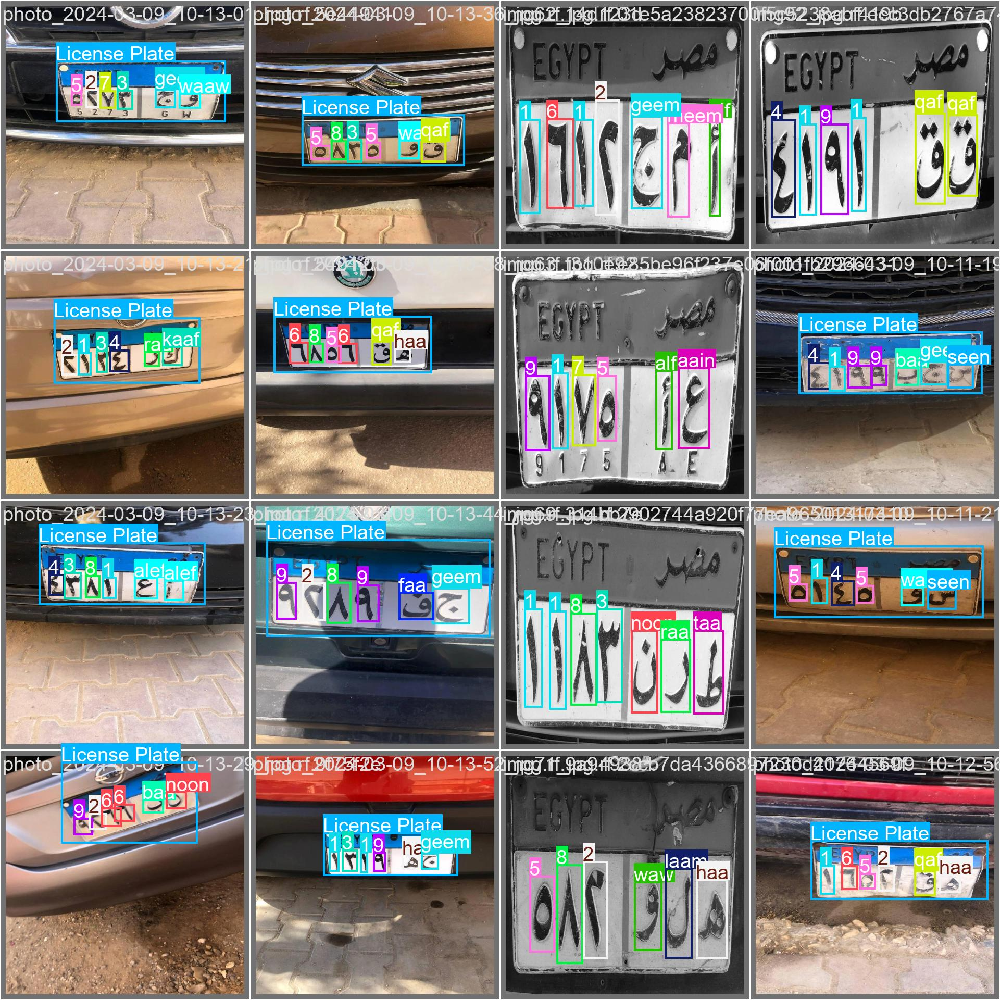

Displaying: /kaggle/working/runs/train/yolov8m_car_plate2/train_batch6242.jpg


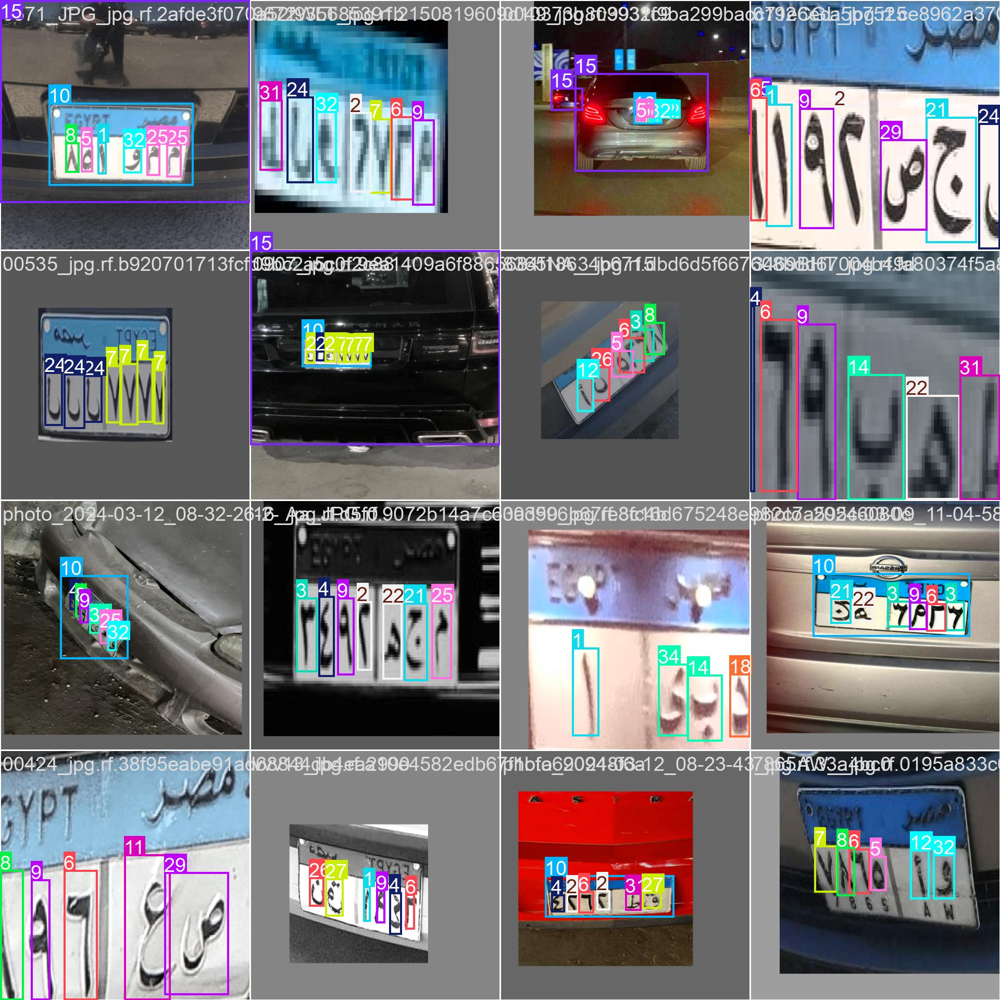

In [ ]:
import os
from IPython.display import display, Image

# Path to the training results directory
results_dir = "/kaggle/working/runs/train/yolov8m_car_plate2"

# List all files in the directory
visualization_files = [os.path.join(results_dir, file) for file in os.listdir(results_dir) if file.endswith(('.jpg', '.png'))]

# Display all visualization images
if visualization_files:
    for file in visualization_files:
        print(f"Displaying: {file}")
        display(Image(filename=file))
else:
    print("No visualization images found in the specified directory.")



image 1/1 /kaggle/input/egyptian-cars-plates/EALPR Vechicles dataset/Vehicles/0014.jpg: 640x384 1 1, 1 4, 1 5, 1 8, 1 License Plate, 1 car, 1 raa, 1 waaw, 1 yaa, 46.6ms
Speed: 2.1ms preprocess, 46.6ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 384)


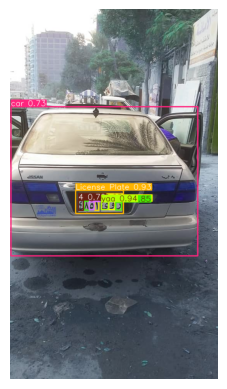

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt

# Path to the trained model weights
model_path = '/kaggle/working/runs/train/yolov8m_car_plate2/weights/best.pt'

# Load the YOLO model
model_ocr = YOLO(model_path)

# # Verify that the model is loaded correctly
# print("Loaded Model:")
# print(model_ocr)

# Path to the test image
resize_image1 = '/kaggle/input/egyptian-cars-plates/EALPR Vechicles dataset/Vehicles/0014.jpg'

# Run prediction on the image
result = model_ocr.predict(source=resize_image1, conf=0.20)

# Assuming 'result' contains the predictions and the image
predicted_image = result[0].plot()  # Plotting the result image

# Display the image using Matplotlib
plt.imshow(predicted_image)
plt.axis('off')  # Hide the axis
plt.show()


In [ ]:
# Define a mapping from English class names to Arabic class names and numbers
arabic_mapping = {
    "aain": "أ",
    "alef": "ا",
    "alf": "ألف",
    "baa": "ب",
    "daal": "د",
    "dal": "ذ",
    "e": "ع",
    "faa": "ف",
    "geem": "ج",
    "haa": "ه",
    "kaaf": "ك",
    "laam": "ل",
    "meem": "م",
    "noon": "ن",
    "qaf": "ق",
    "raa": "ر",
    "sad": "ص",
    "seen": "س",
    "taa": "ت",
    "waaw": "و",
    "waw": "ؤ",
    "yaa": "ي",
    # Numbers (assuming model outputs digits as text)
    "0": "٠",  # Arabic numeral for 0
    "1": "١",  # Arabic numeral for 1
    "2": "٢",
    "3": "٣",
    "4": "٤",
    "5": "٥",
    "6": "٦",
    "7": "٧",
    "8": "٨",
    "9": "٩",
}

In [ ]:
# Path to the image
resize_image1 = '/kaggle/input/egyptian-cars-plates/EALPR Vechicles dataset/Vehicles/0001.jpg'

# Assuming 'result' is the output from the model
detected_letters = []
detected_numbers = []

# Accessing the detected boxes and arranging by x-coordinate for correct order
boxes = result[0].boxes
detections = []

# Extract Arabic letters and numbers with their positions
for box in boxes:
    # 'box.cls' holds the class ID for each detected box
    class_id = int(box.cls)  # Convert the class ID to integer if needed

    # Look up the class ID in the 'names' dictionary to get the recognized text
    if class_id in result[0].names:
        recognized_text = result[0].names[class_id]

        # Translate recognized text to Arabic if available
        arabic_text = arabic_mapping.get(recognized_text, None)

        # Exclude non-Arabic classes (e.g., cars, license plates)
        if arabic_text:
            x1, _, x2, _ = box.xyxy[0]  # Get x-coordinates of the box
            center_x = (x1 + x2) / 2  # Calculate center x-coordinate
            detections.append((center_x, arabic_text))

# Arrange detected characters (letters and numbers) by their x-coordinates
detections.sort(key=lambda x: x[0])  # Sort by center_x
detected_characters = [char for _, char in detections]  # Extract only characters

# Separate letters and numbers into different lists
for char in detected_characters:
    if char.isdigit():  # Check if the character is a digit
        detected_numbers.append(char)
    else:
        detected_letters.append(char)

# Reverse both lists to fix mirrored order (right-to-left for Arabic text)
detected_letters.reverse()
detected_numbers.reverse()

# Join letters and numbers with spaces
letters_output = " ".join(detected_letters)
numbers_output = " ".join(detected_numbers)

# Print the detected letters and numbers
print("Detected Letters (Arabic, arranged):", letters_output)
print("Detected Numbers (Arabic, arranged):", numbers_output)


Detected Letters (Arabic, arranged): ر و ي
Detected Numbers (Arabic, arranged): ١ ٥ ٨ ٤
